In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_excel('/content/drive/MyDrive/BlinkIT Grocery Data.xlsx')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [116]:
category_summary = df.groupby("Item Type").agg(
    Total_Records=("Item Identifier", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean")
).sort_values("Total_Sales", ascending=False)

category_summary

,Total_Records,Total_Sales,Average_Sales
Item Type,,,
Fruits and Vegetables,1232,178124.0810,144.581235
Snack Foods,1200,175433.9224,146.194935
Household,910,135976.5254,149.424753
Frozen Foods,856,118558.8814,138.503366
Dairy,682,101276.4616,148.499211
Canned,649,90706.7290,139.763835
Baking Goods,648,81894.7364,126.380766
Health and Hygiene,520,68025.8388,130.818921
Meat,425,59449.8638,139.882032


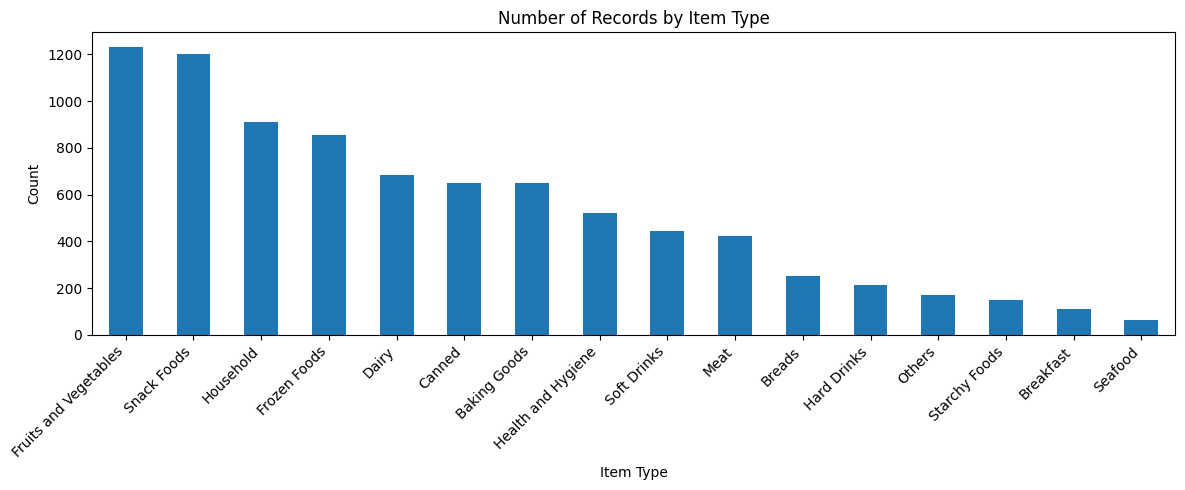

In [117]:
#task1.1
df["Item Type"].value_counts().plot(
    kind="bar", figsize=(12, 5)
)

plt.title("Number of Records by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [118]:
#task1.2
outlet_summary = df.groupby("Outlet Type").agg(
    Total_Records=("Outlet Identifier", "count"),
    Unique_Outlets=("Outlet Identifier", "nunique"),
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Average_Rating=("Rating", "mean")
).sort_values("Total_Sales", ascending=False)

outlet_summary

,Total_Records,Unique_Outlets,Total_Sales,Average_Sales,Average_Rating
Outlet Type,,,,,
Supermarket Type1,5577,6,787549.8928,141.213895,3.963242
Grocery Store,1083,2,151939.1490,140.294690,3.985873
Supermarket Type2,928,1,131477.7764,141.678638,3.971228
Supermarket Type3,935,1,130714.6746,139.801791,3.952941


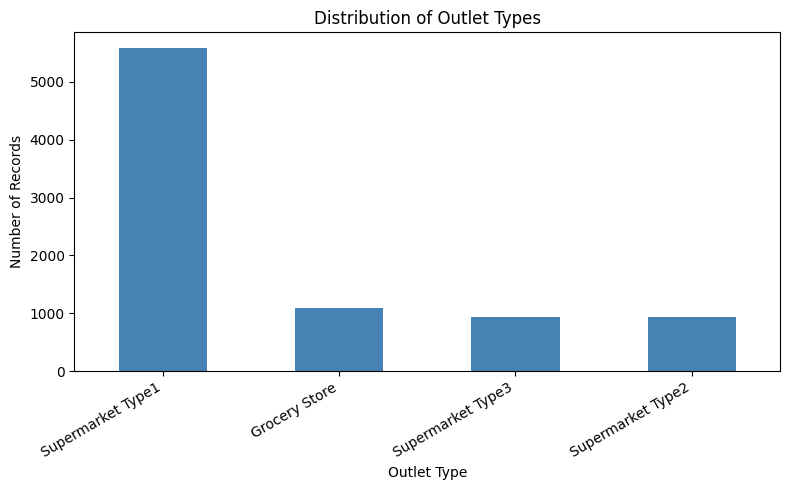

In [119]:
df["Outlet Type"].value_counts().plot(
    kind="bar", color="steelblue", figsize=(8, 5)
)

plt.title("Distribution of Outlet Types")
plt.xlabel("Outlet Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [120]:
#task1.3
sales_summary = pd.Series({
    "Total Sales": df["Sales"].sum(),
    "Average Sales": df["Sales"].mean(),
    "Median Sales": df["Sales"].median(),
    "Minimum Sales": df["Sales"].min(),
    "Maximum Sales": df["Sales"].max(),
    "Total Records": len(df)
})

sales_summary

,0
Total Sales,1.201681e+06
Average Sales,1.409928e+02
Median Sales,1.430128e+02
Minimum Sales,3.129000e+01
Maximum Sales,2.668884e+02
Total Records,8.523000e+03


In [121]:
#task1.4
top_10_items = (
    df.groupby("Item Identifier")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_10_items

,Sales
Item Identifier,
FDU12,2371.0112
FDT07,2306.8970
NCQ06,2294.7126
FDL58,2111.6544
NCB31,2104.7280
FDX31,2104.4622
FDF05,2103.1280
FDR59,2096.5752
FDP28,2087.8488


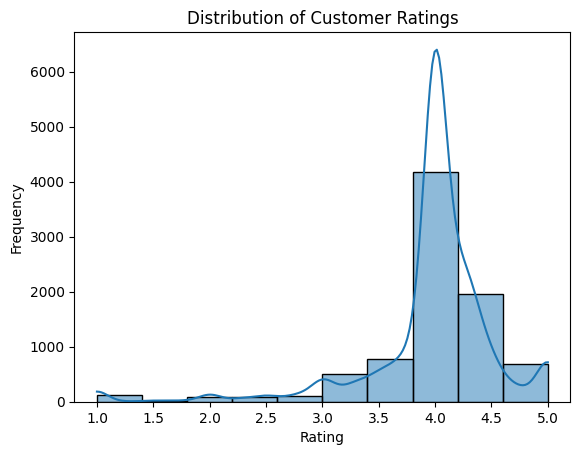

In [122]:
sns.histplot(data=df, x="Rating", bins=10, kde=True)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

In [123]:
#task2.1
df.isnull().sum()

,0
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,1463


In [124]:
df["Item Weight"] = df["Item Weight"].fillna(
    df["Item Weight"].median()
)
df["Outlet Size"] = df["Outlet Size"].fillna(
    df["Outlet Size"].mode()[0]
)

In [125]:
df.isnull().sum()


,0
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,0


In [126]:
#task2.2
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
8518,False
8519,False
8520,False
8521,False


In [127]:
#task2.3
# Inspect numerical columns
df[["Item Weight", "Item Visibility", "Sales", "Rating"]].describe()

,Item Weight,Item Visibility,Sales,Rating
count,8523.00000,8523.000000,8523.000000,8523.000000
mean,12.81342,0.066132,140.992783,3.965857
std,4.22724,0.051598,62.275067,0.605651
min,4.55500,0.000000,31.290000,1.000000
25%,9.31000,0.026989,93.826500,4.000000
50%,12.60000,0.053931,143.012800,4.000000
75%,16.00000,0.094585,185.643700,4.200000
max,21.35000,0.328391,266.888400,5.000000


In [128]:
def find_outliers(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]
    return outliers, lower_limit, upper_limit

In [129]:
sales_outliers, lower, upper = find_outliers("Sales")
print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(sales_outliers))
sales_outliers.head()

Lower limit: -43.8993
Upper limit: 323.3695
Number of outliers: 0


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


In [130]:
for column in ["Item Weight", "Item Visibility", "Sales", "Rating"]:
    outliers, lower, upper = find_outliers(column)
    print(
        column,
        "| Outliers:", len(outliers),
        "| Lower limit:", lower,
        "| Upper limit:", upper
    )

Item Weight | Outliers: 0 | Lower limit: -0.7249999999999996 | Upper limit: 26.035
Item Visibility | Outliers: 144 | Lower limit: -0.07440424500000001 | Upper limit: 0.195979015
Sales | Outliers: 0 | Lower limit: -43.8993 | Upper limit: 323.3695
Rating | Outliers: 1931 | Lower limit: 3.6999999999999997 | Upper limit: 4.5


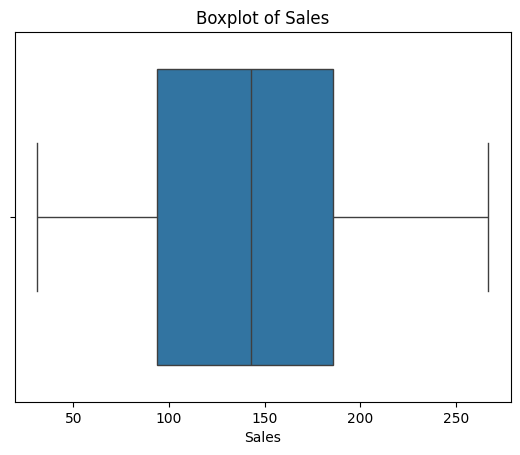

In [131]:
sns.boxplot(data=df, x="Sales")
plt.title("Boxplot of Sales")
plt.show()

In [132]:
#task2.4
df["Item Fat Content"].value_counts(dropna=False)

,count
Item Fat Content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112


In [133]:
df["Item Fat Content"] = (
    df["Item Fat Content"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "lf": "low fat",
        "reg": "regular"
    })
    .str.title()
)

In [134]:
df["Item Fat Content"].value_counts(dropna=False)

,count
Item Fat Content,
Low Fat,5517
Regular,3006


In [135]:
categorical_columns = [
    "Item Identifier",
    "Item Type",
    "Outlet Identifier",
    "Outlet Location Type",
    "Outlet Size",
    "Outlet Type"
]
for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip()

In [136]:
df.dtypes

,0
Item Fat Content,string[python]
Item Identifier,string[python]
Item Type,string[python]
Outlet Establishment Year,int64
Outlet Identifier,string[python]
Outlet Location Type,string[python]
Outlet Size,string[python]
Outlet Type,string[python]
Item Visibility,float64
Item Weight,float64


In [137]:
numeric_columns = [
    "Outlet Establishment Year",
    "Item Visibility",
    "Item Weight",
    "Sales",
    "Rating"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [138]:
df[~df["Rating"].between(0, 5) & df["Rating"].notna()]
df[df["Sales"] < 0]
df[df["Item Weight"] < 0]

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


In [139]:
#task3.1
sales_by_item = (
    df.groupby("Item Type")["Sales"]
    .sum()
    .sort_values(ascending=False)
)
sales_by_item
sales_by_item.idxmax(), sales_by_item.max()

('Fruits and Vegetables', 178124.081)

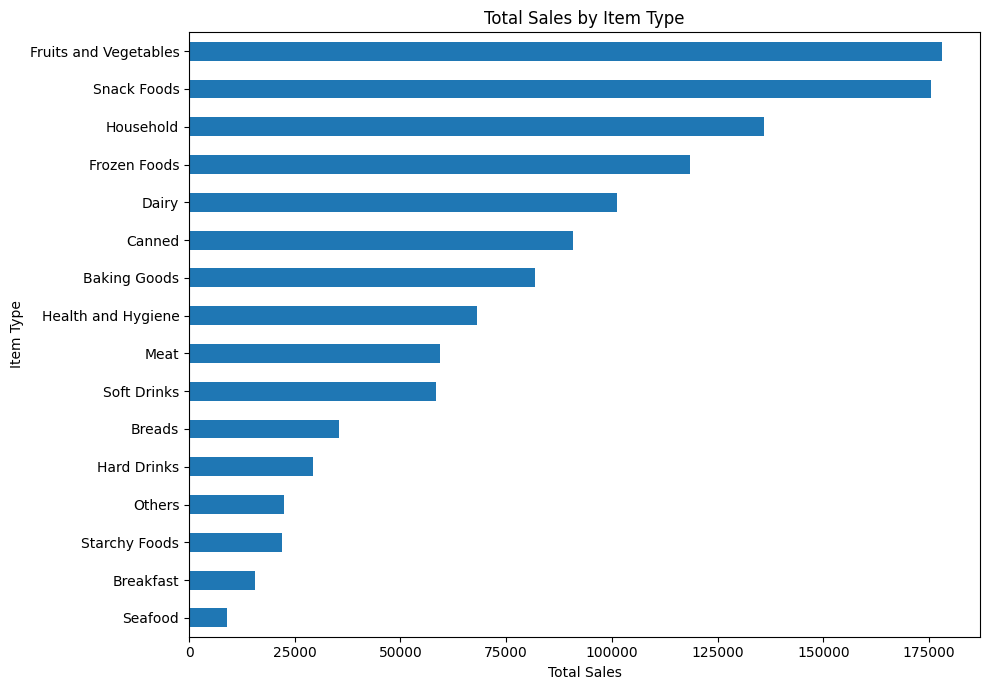

In [140]:
sales_by_item.sort_values().plot(
    kind="barh", figsize=(10, 7)
)

plt.title("Total Sales by Item Type")
plt.xlabel("Total Sales")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

In [141]:
#task3.2
sales_by_outlet = (
    df.groupby("Outlet Type")["Sales"]
    .sum()
    .sort_values(ascending=False)
)
sales_by_outlet
sales_by_outlet.idxmax(), sales_by_outlet.max()

('Supermarket Type1', 787549.8928)

In [142]:
df.groupby("Outlet Type")["Sales"]

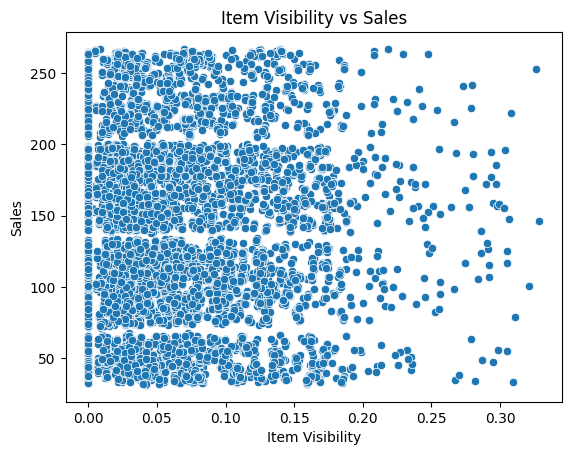

In [143]:
#task3.3
df[["Item Visibility", "Sales"]].corr()
sns.scatterplot(data=df, x="Item Visibility", y="Sales")
plt.title("Item Visibility vs Sales")
plt.show()

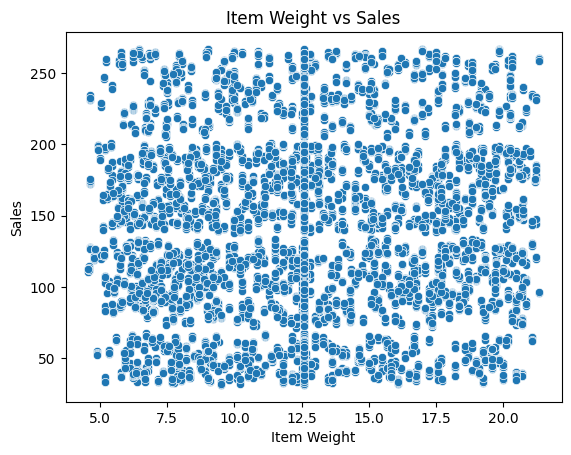

In [144]:
df[["Item Weight", "Sales"]].corr()
sns.scatterplot(data=df, x="Item Weight", y="Sales")
plt.title("Item Weight vs Sales")
plt.show()

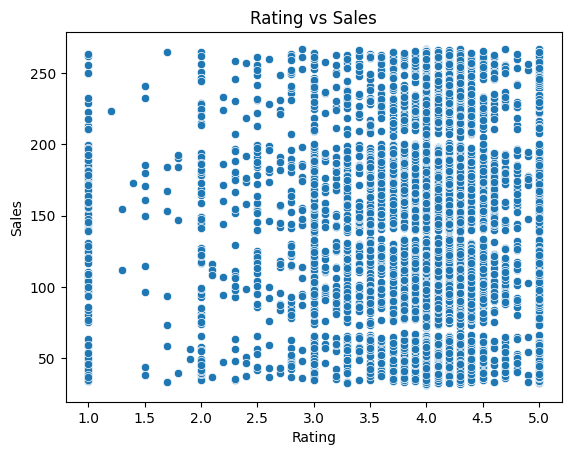

In [145]:
df[["Rating", "Sales"]].corr()
sns.scatterplot(data=df, x="Rating", y="Sales")
plt.title("Rating vs Sales")
plt.show()

In [146]:
df.groupby("Outlet Type")["Sales"].sum().sort_values(ascending=False)

,Sales
Outlet Type,
Supermarket Type1,787549.8928
Grocery Store,151939.1490
Supermarket Type2,131477.7764
Supermarket Type3,130714.6746


In [147]:
df.groupby("Outlet Location Type")["Sales"].sum().sort_values(ascending=False)

,Sales
Outlet Location Type,
Tier 3,472133.0332
Tier 2,393150.6476
Tier 1,336397.8120


In [148]:
df.groupby("Outlet Size")["Sales"].sum().sort_values(ascending=False)

,Sales
Outlet Size,
Medium,507895.7364
Small,444794.1704
High,248991.5860


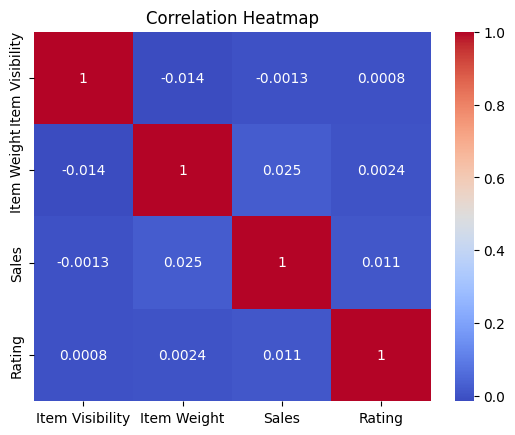

In [149]:
sns.heatmap(
    df[["Item Visibility", "Item Weight", "Sales", "Rating"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

In [150]:
#task3.4
df.groupby("Item Identifier")["Sales"].sum().nlargest(10)

,Sales
Item Identifier,
FDU12,2371.0112
FDT07,2306.8970
NCQ06,2294.7126
FDL58,2111.6544
NCB31,2104.7280
FDX31,2104.4622
FDF05,2103.1280
FDR59,2096.5752
FDP28,2087.8488


In [151]:
df.groupby("Item Identifier")["Sales"].sum().nsmallest(10)

,Sales
Item Identifier,
NCC55,72.8696
FDF38,80.2276
FDN52,86.9198
FDE52,88.9514
NCR42,101.0700
NCF55,104.0622
FDM38,107.8964
DRL59,109.3596
FDU09,109.4912


In [152]:
df.groupby("Outlet Identifier")["Sales"].sum().nlargest(5)

,Sales
Outlet Identifier,
OUT035,133103.9070
OUT046,132113.3698
OUT013,131809.0156
OUT018,131477.7764
OUT045,130942.7802


In [153]:
df.groupby("Outlet Identifier")["Sales"].sum().nsmallest(5)

,Sales
Outlet Identifier,
OUT019,73807.5824
OUT010,78131.5666
OUT017,129103.9604
OUT049,130476.8598
OUT027,130714.6746


In [154]:
median_sales = df["Sales"].median()

df["Sales Performance"] = np.where(
    df["Sales"] >= median_sales,
    "High Sales",
    "Low Sales"
)
df.groupby("Sales Performance")[
    ["Item Visibility", "Item Weight", "Rating", "Sales"]
].mean()

,Item Visibility,Item Weight,Rating,Sales
Sales Performance,,,,
High Sales,0.066460,12.919239,3.972759,193.503513
Low Sales,0.065804,12.707576,3.958953,88.469730


In [155]:
#task4.1
df.groupby("Item Type")["Sales"].sum().sort_values(ascending=False)

,Sales
Item Type,
Fruits and Vegetables,178124.0810
Snack Foods,175433.9224
Household,135976.5254
Frozen Foods,118558.8814
Dairy,101276.4616
Canned,90706.7290
Baking Goods,81894.7364
Health and Hygiene,68025.8388
Meat,59449.8638


In [156]:
category_sales = df.groupby("Item Type")["Sales"].sum()

(category_sales / df["Sales"].sum() * 100).sort_values(
    ascending=False
)

,Sales
Item Type,
Fruits and Vegetables,14.822903
Snack Foods,14.599037
Household,11.315521
Frozen Foods,9.866082
Dairy,8.427896
Canned,7.548317
Baking Goods,6.815012
Health and Hygiene,5.660888
Meat,4.947223


In [157]:
df.groupby("Item Identifier")["Sales"].sum().nlargest(10)

,Sales
Item Identifier,
FDU12,2371.0112
FDT07,2306.8970
NCQ06,2294.7126
FDL58,2111.6544
NCB31,2104.7280
FDX31,2104.4622
FDF05,2103.1280
FDR59,2096.5752
FDP28,2087.8488


In [158]:
#task4.2
df.groupby("Outlet Identifier")["Sales"].sum().sort_values(
    ascending=False
)

,Sales
Outlet Identifier,
OUT035,133103.9070
OUT046,132113.3698
OUT013,131809.0156
OUT018,131477.7764
OUT045,130942.7802
OUT027,130714.6746
OUT049,130476.8598
OUT017,129103.9604
OUT010,78131.5666


In [159]:
df.groupby("Outlet Type")["Sales"].sum().sort_values(
    ascending=False
)

,Sales
Outlet Type,
Supermarket Type1,787549.8928
Grocery Store,151939.1490
Supermarket Type2,131477.7764
Supermarket Type3,130714.6746


In [160]:
df.groupby("Outlet Location Type")["Sales"].sum().sort_values(
    ascending=False
)

,Sales
Outlet Location Type,
Tier 3,472133.0332
Tier 2,393150.6476
Tier 1,336397.8120


In [161]:
df.groupby("Outlet Identifier")["Rating"].mean().sort_values(
    ascending=False
)

,Rating
Outlet Identifier,
OUT019,3.995076
OUT049,3.985484
OUT017,3.981641
OUT010,3.977117
OUT018,3.971228
OUT045,3.959957
OUT046,3.958387
OUT027,3.952941
OUT013,3.949571


In [162]:
df.groupby("Item Type")["Sales"].sum().nsmallest(5)

,Sales
Item Type,
Seafood,9077.8700
Breakfast,15596.6966
Starchy Foods,21880.0274
Others,22451.8916
Hard Drinks,29334.6806


In [163]:
df.groupby("Outlet Identifier")["Sales"].sum().nsmallest(5)

,Sales
Outlet Identifier,
OUT019,73807.5824
OUT010,78131.5666
OUT017,129103.9604
OUT049,130476.8598
OUT027,130714.6746


In [164]:
df.groupby("Item Type")["Rating"].mean().nsmallest(5)

,Rating
Item Type,
Breads,3.881275
Hard Drinks,3.907477
Starchy Foods,3.920270
Soft Drinks,3.920674
Breakfast,3.932727


In [165]:
df.groupby("Sales Performance")[
    ["Item Visibility", "Item Weight", "Rating"]
].mean()

,Item Visibility,Item Weight,Rating
Sales Performance,,,
High Sales,0.066460,12.919239,3.972759
Low Sales,0.065804,12.707576,3.958953


In [166]:
#task4.4
df.groupby("Item Type")["Sales"].sum().nlargest(5)

,Sales
Item Type,
Fruits and Vegetables,178124.0810
Snack Foods,175433.9224
Household,135976.5254
Frozen Foods,118558.8814
Dairy,101276.4616


In [167]:
df.groupby("Outlet Type")["Sales"].sum().sort_values(ascending=False)

,Sales
Outlet Type,
Supermarket Type1,787549.8928
Grocery Store,151939.1490
Supermarket Type2,131477.7764
Supermarket Type3,130714.6746


In [168]:
df.groupby("Outlet Location Type")["Sales"].sum().sort_values(ascending=False)

,Sales
Outlet Location Type,
Tier 3,472133.0332
Tier 2,393150.6476
Tier 1,336397.8120


In [169]:
df.groupby("Item Type")["Rating"].mean().nlargest(5)

,Rating
Item Type,
Meat,4.023059
Household,3.998681
Canned,3.994299
Health and Hygiene,3.986154
Baking Goods,3.983025


In [170]:
df.to_excel("BlinkIT_Analysis_Results.xlsx", index=False)